# Практика 2. Декомпозиция и сглаживание
## Сравнение методов на рядах со сложной сезонностью

**Цель**: на одном и том же ряду применить классическую декомпозицию, STL и MSTL и
показать, как выбор метода влияет на компоненты и на интерпретацию.

**Шаги:**
1. **Визуальный анализ**. Построить весь ряд, суточные и недельные подсерии,
heatmap «час × день недели».
2. **ACF.** Убедиться, что пики есть на лагах 24 и 168 - это подтверждает две
сезонности.
3. **Классическая декомпозиция** с `period=24` . Показать, что недельный цикл
остаётся в остатке: на графике остатка будет видна недельная структура.
4. **STL** с `period=24` , `robust=True` . Сравнить остаток с классической декомпозицией:
недельная структура всё ещё присутствует, но суточная выделена лучше.
5. **MSTL** с `periods=(24, 168)` , `robust=True` . Показать, что обе сезонности
выделены, остаток стал заметно чище (меньше дисперсия, нет недельной
структуры).
6. **Количественное сравнение:**
    - дисперсия остатка для каждого метода;
    - наличие автокорреляции в остатке на лагах 24 и 168 (ACF остатка);
    - визуальная чистота компонент.
7. **Интерпретация.** Обсудить, какая сезонная компонента соответствует суточному
профилю, какая - недельному, и как выглядит тренд после удаления обеих
сезонностей.
8. **Вывод.** Сформулировать, в каких задачах достаточно классики, когда нужен STL, а
когда обязателен MSTL.

**Источник данных:** `ts_source.csv` - CSV-выгрузка генератора
`generate_time_series(...)` из `lab_ts_generator.ipynb`.
Формат `timestamp,value`, шаг 5 мин, **26208 строк = 91 день**.

**Параметры генерации:** `variance='grow'`, `trend='slow_up'`,
`seasonality='two'`,
`season_1_type='day',  season_1_size=1` → **суточная** сезонность (24 ч = 288 точек 5-мин),
`season_2_type='week', season_2_size=1` → **недельная** сезонность (168 ч = 2016 точек 5-мин).

После ресемплинга до 1 ч в ряду **две** сезонности с периодами 24 ч и 168 ч.


In [25]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf

np.random.seed(42)
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
%matplotlib inline

SOURCE_CSV = 'ts_source.csv'

GENERATOR_PARAMS = {
    'n_points':      91 * 24 * 12,           # 26208
    'variance':      'grow',
    'trend':         'slow_up',
    'seasonality':   'two',
    'season_1_type': 'day',  'season_1_size': 1,   # 24 ч
    'season_2_type': 'week', 'season_2_size': 1,   # 168 ч
    'random_state':  42,
}
PERIOD_DAILY  = 24
PERIOD_WEEKLY = 168

print('Параметры генератора:')
for k, v in GENERATOR_PARAMS.items():
    print(f'  {k:15s} = {v!r}')
print(f'\nПериоды после ресемплинга: {SEASON_1_PERIOD_H} ч и {SEASON_2_PERIOD_H} ч')

Параметры генератора:
  n_points        = 26208
  variance        = 'grow'
  trend           = 'slow_up'
  seasonality     = 'two'
  season_1_type   = 'day'
  season_1_size   = 1
  season_2_type   = 'week'
  season_2_size   = 1
  random_state    = 42

Периоды после ресемплинга: 24 ч и 168 ч


## Шаг 0. Загрузка, ресемплинг до 1 ч

- 26208 строк с шагом 5 мин → после `.resample('h').mean()` получаем **2184** часовые точки (91 сутки = 13 недель).

In [26]:
if not os.path.exists(SOURCE_CSV):
    raise FileNotFoundError(f'Не найден {SOURCE_CSV!r}.')

raw = pd.read_csv(SOURCE_CSV, parse_dates=['timestamp'])
raw = raw.sort_values('timestamp').drop_duplicates('timestamp').reset_index(drop=True)

print(f'Строк в файле: {len(raw)}')
print(f'Период: {raw["timestamp"].min()} - {raw["timestamp"].max()}')

s_5m = raw.set_index('timestamp')['value'].rename('y')
s_1h = s_5m.resample('h').mean().rename('y')
s_1h = s_1h.interpolate(method='linear').bfill().ffill()   # страховка

print(f'Точек 5-мин: {len(s_5m)}')
print(f'Точек 1-ч:   {len(s_1h)}  (ожидается 2184 = 91*24)')
print(f'NaN:         {s_1h.isna().sum()}')

df = s_1h.to_frame()

Строк в файле: 26208
Период: 2026-11-27 00:00:00 - 2027-02-25 23:55:00
Точек 5-мин: 26208
Точек 1-ч:   2184  (ожидается 2184 = 91*24)
NaN:         0


## Шаг 1. Визуальный анализ

1. **Весь ряд** - общий обзор.
2. **Суточные подсерии** - среднее по часу дня.
3. **Недельные подсерии** - среднее по дню недели.
4. **Heatmap "час × день недели"** - обе сезонности одновременно.

**Ожидание:**
- суточная: амплитуда ≈ 13, форма `sin`, max ≈ 06:00, min ≈ 17:00;
- недельная: амплитуда ≈ 65 (в 5 раз сильнее суточной);
- 91 сутки = 13 недель → недельный профиль **не искажён** трендом.

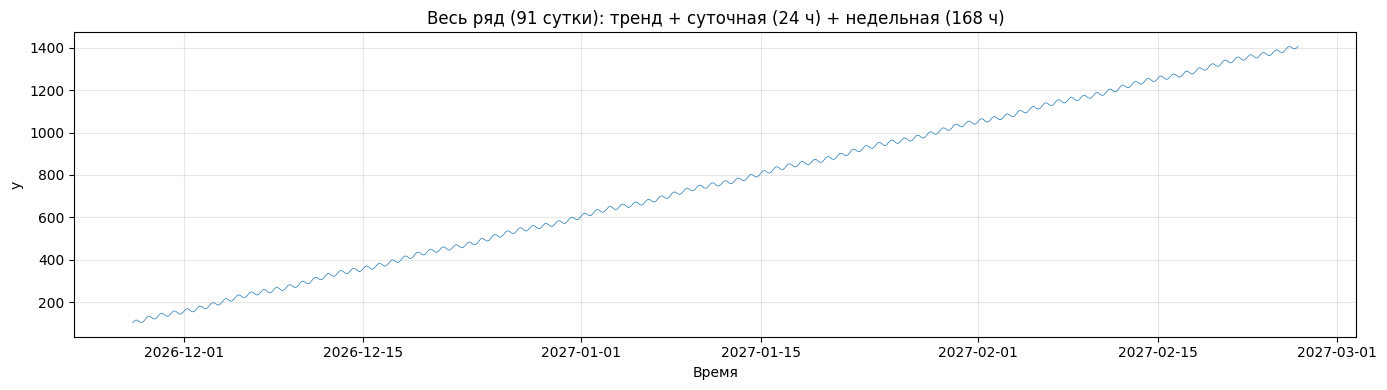

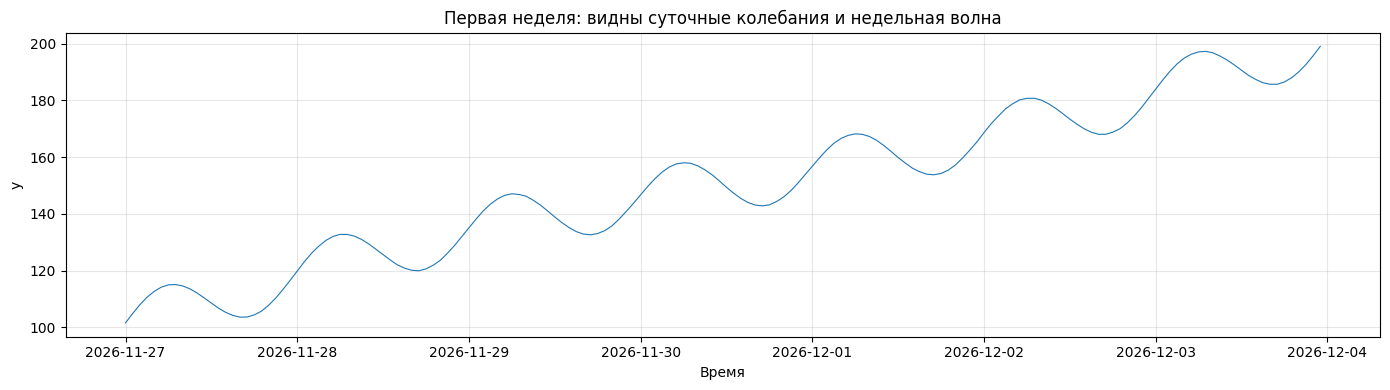

In [27]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df.index, df['y'], linewidth=0.5)
ax.set_title('Весь ряд (91 сутки): тренд + суточная (24 ч) + недельная (168 ч)')
ax.set_xlabel('Время'); ax.set_ylabel('y')
plt.tight_layout(); plt.show()

week = df.iloc[:24 * 7]
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(week.index, week['y'], linewidth=0.8)
ax.set_title('Первая неделя: видны суточные колебания и недельная волна')
ax.set_xlabel('Время'); ax.set_ylabel('y')
plt.tight_layout(); plt.show()

Суточная сезонность: амплитуда ≈ 13.15
  max в 06:00, min в 17:00


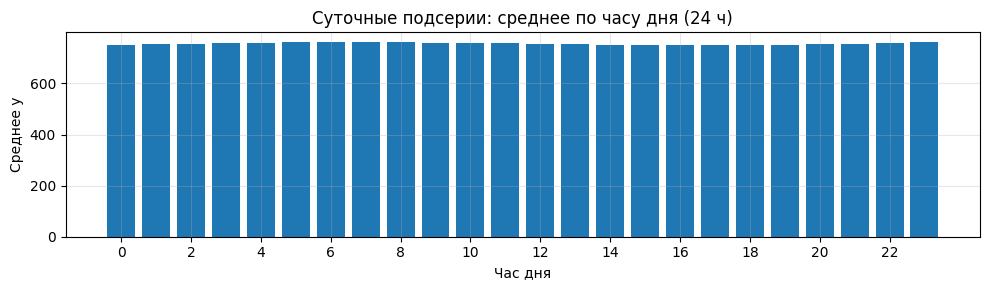


Недельная сезонность: амплитуда ≈ 82.22
  max в Чт, min в Пт


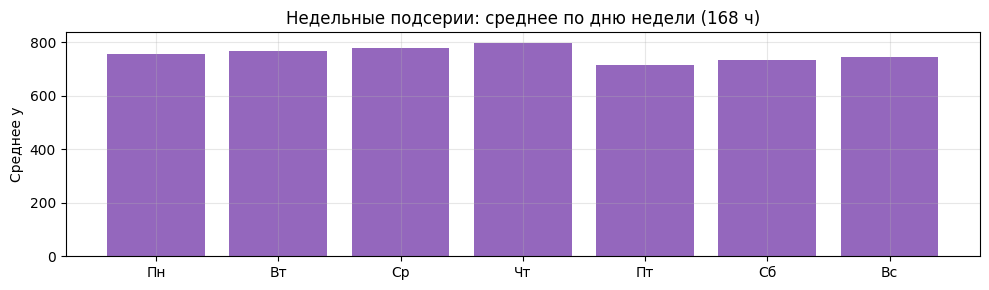

In [28]:
hourly = df.groupby(df.index.hour)['y'].mean()
print(f'Суточная сезонность: амплитуда ≈ {hourly.max() - hourly.min():.2f}')
print(f'  max в {hourly.idxmax():02d}:00, min в {hourly.idxmin():02d}:00')

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(hourly.index, hourly.values, color='tab:blue')
ax.set_xticks(range(0, 24, 2))
ax.set_title('Суточные подсерии: среднее по часу дня (24 ч)')
ax.set_xlabel('Час дня'); ax.set_ylabel('Среднее y')
plt.tight_layout(); plt.show()

dow_names = ['Пн','Вт','Ср','Чт','Пт','Сб','Вс']
dow = df.groupby(df.index.dayofweek)['y'].mean().reindex(range(7))
print(f'\nНедельная сезонность: амплитуда ≈ {dow.max() - dow.min():.2f}')
print(f'  max в {dow_names[dow.idxmax()]}, min в {dow_names[dow.idxmin()]}')

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(dow_names, dow.values, color='tab:purple')
ax.set_title('Недельные подсерии: среднее по дню недели (168 ч)')
ax.set_ylabel('Среднее y')
plt.tight_layout(); plt.show()

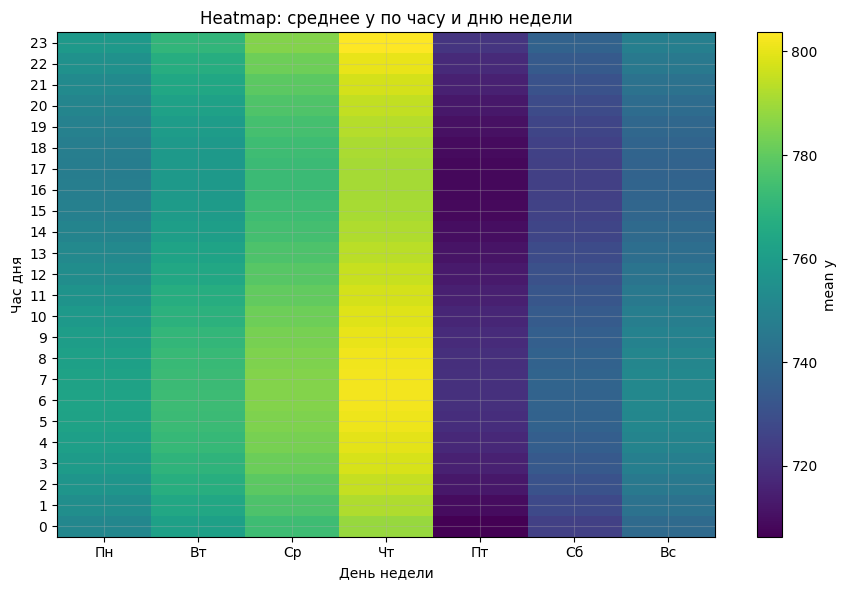

In [29]:
tmp = df.assign(hour=df.index.hour, dow=df.index.dayofweek)
pivot = tmp.pivot_table(values='y', index='hour', columns='dow', aggfunc='mean')

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(pivot.values, aspect='auto', cmap='viridis', origin='lower')
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index)
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels([dow_names[c] for c in pivot.columns])
ax.set_xlabel('День недели'); ax.set_ylabel('Час дня')
ax.set_title('Heatmap: среднее y по часу и дню недели')
plt.colorbar(im, ax=ax, label='mean y')
plt.tight_layout(); plt.show()

## Шаг 2. ACF: подтверждение периодов сезонности

**Зачем.** MSTL требует **явно** задавать `periods`. Прежде чем передавать
`periods=(24, 168)`, нужно убедиться, что именно на этих лагах в ACF есть пики.

**Что ожидаем:**
- **ACF исходного ряда** - нестационарен (медленное затухание), пики каждые 24 ч,
  недельный пик на 168 «тонет» в тренде.
- **ACF после `diff`** (линейный тренд удалён) - чёткие пики на 24, 48, …, 168;
  между пиками ACF уходит в минус.

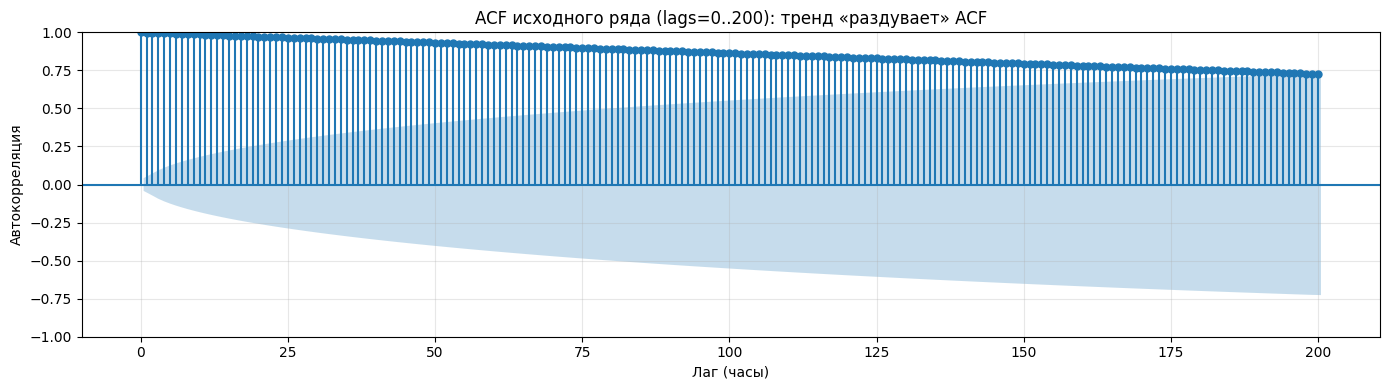

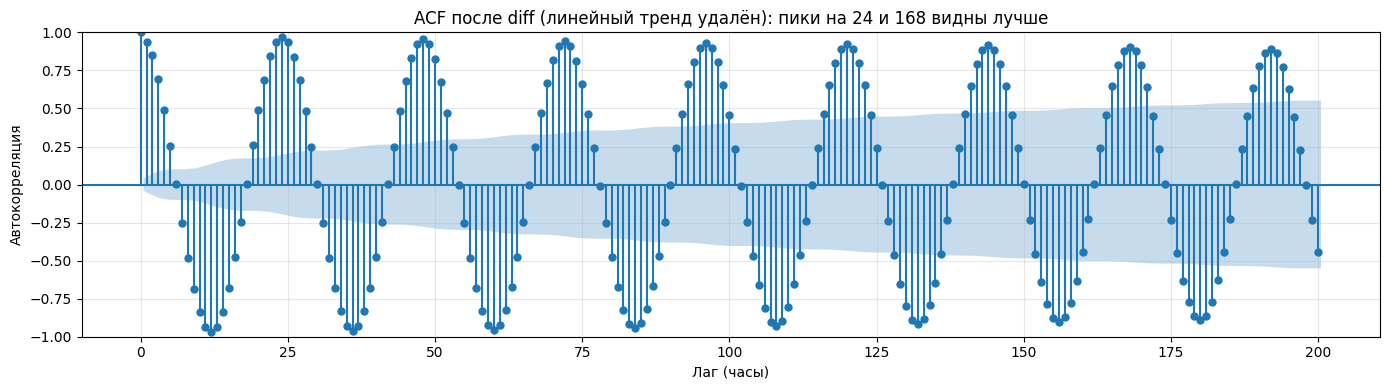

In [30]:
fig, ax = plt.subplots(figsize=(14, 4))
plot_acf(df['y'].dropna(), lags=200, ax=ax, alpha=0.05)
ax.set_title('ACF исходного ряда (lags=0..200): тренд «раздувает» ACF')
ax.set_xlabel('Лаг (часы)'); ax.set_ylabel('Автокорреляция')
plt.tight_layout(); plt.show()

dy = df['y'].diff().dropna()
fig, ax = plt.subplots(figsize=(14, 4))
plot_acf(dy, lags=200, ax=ax, alpha=0.05)
ax.set_title('ACF после diff (линейный тренд удалён): пики на 24 и 168 видны лучше')
ax.set_xlabel('Лаг (часы)'); ax.set_ylabel('Автокорреляция')
plt.tight_layout(); plt.show()

In [31]:
acf_vals = acf(dy, nlags=200, fft=True)
for lag in [1, 12, 24, 48, 72, 96, 168, 336]:
    if lag < len(acf_vals):
        print(f'ACF(lag={lag:3d}) = {acf_vals[lag]:+.4f}')

def local_peak(acf_vals, center, radius=3):
    lo, hi = max(0, center - radius), min(len(acf_vals), center + radius + 1)
    idx = lo + int(np.argmax(acf_vals[lo:hi]))
    return idx, acf_vals[idx]

lag24, v24 = local_peak(acf_vals, 24, radius=3)
lag168, v168 = local_peak(acf_vals, 168, radius=5)
print(f'\nЛокальный максимум около 24:  лаг={lag24},  ACF={v24:+.4f}')
print(f'Локальный максимум около 168: лаг={lag168}, ACF={v168:+.4f}')

ACF(lag=  1) = +0.9398
ACF(lag= 12) = -0.9673
ACF(lag= 24) = +0.9706
ACF(lag= 48) = +0.9558
ACF(lag= 72) = +0.9415
ACF(lag= 96) = +0.9302
ACF(lag=168) = +0.9068

Локальный максимум около 24:  лаг=24,  ACF=+0.9706
Локальный максимум около 168: лаг=168, ACF=+0.9068


## Шаг 3. Классическая декомпозиция с `period=24`

**Почему `period=24`, а не 168.** По вашим шагам: сначала выделяем **суточную**
сезонность, и показываем, что **недельный цикл остаётся в остатке**. Это учебный
момент: классическая декомпозиция умеет только один период.

**Ожидание:**
- сезонная компонента - суточная (24 ч);
- в остатке - **недельная структура** (её видно на графике остатка);
- краевой эффект: первые/последние 12 точек тренда - `NaN` (окно 24 ч, чётное → 2×24 MA).

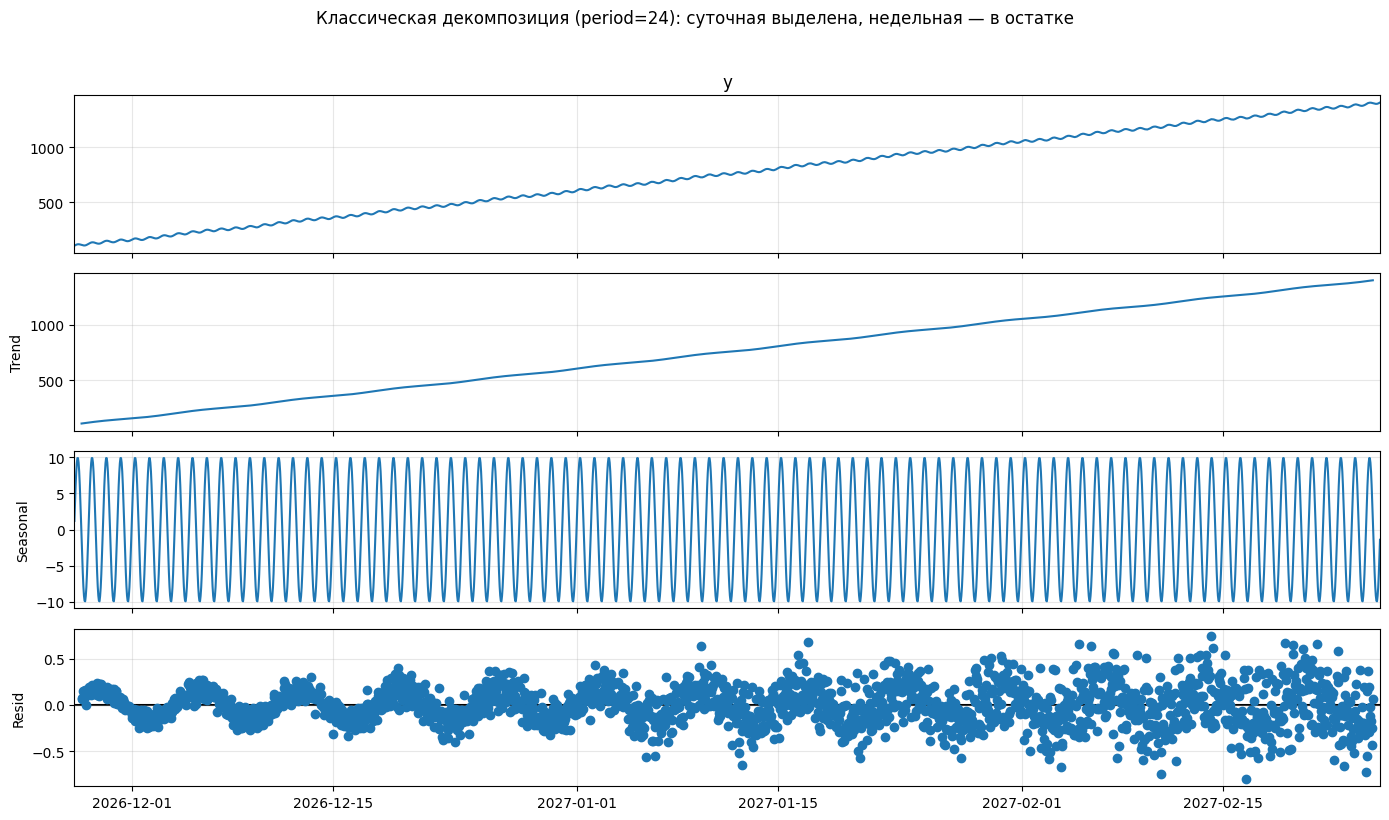

NaN в тренде: 24
NaN в остатке: 24


In [46]:
res_classic_obj = seasonal_decompose(df['y'], model='additive', period=PERIOD_DAILY)
res_classic     = res_classic_obj.resid.dropna()   # Series

fig = res_classic_obj.plot()
fig.set_size_inches(14, 8)
fig.suptitle('Классическая декомпозиция (period=24): суточная выделена, недельная - в остатке', y=1.02)
plt.tight_layout(); plt.show()

print(f'NaN в тренде: {res_classic_obj.trend.isna().sum()}')
print(f'NaN в остатке: {res_classic_obj.resid.isna().sum()}')

## Шаг 4. STL с `period=24, robust=True`

**Почему `period=24`.** Тот же принцип: выделяем суточную, недельная остаётся
в остатке. STL лучше классики по двум причинам:
- сезонность может эволюционировать (`season`);
- `robust=True` уменьшает влияние выбросов.

**Ожидание:**
- суточная компонента **чище**, чем у классики;
- в остатке **всё ещё видна недельная структура** (STL умеет только один период).

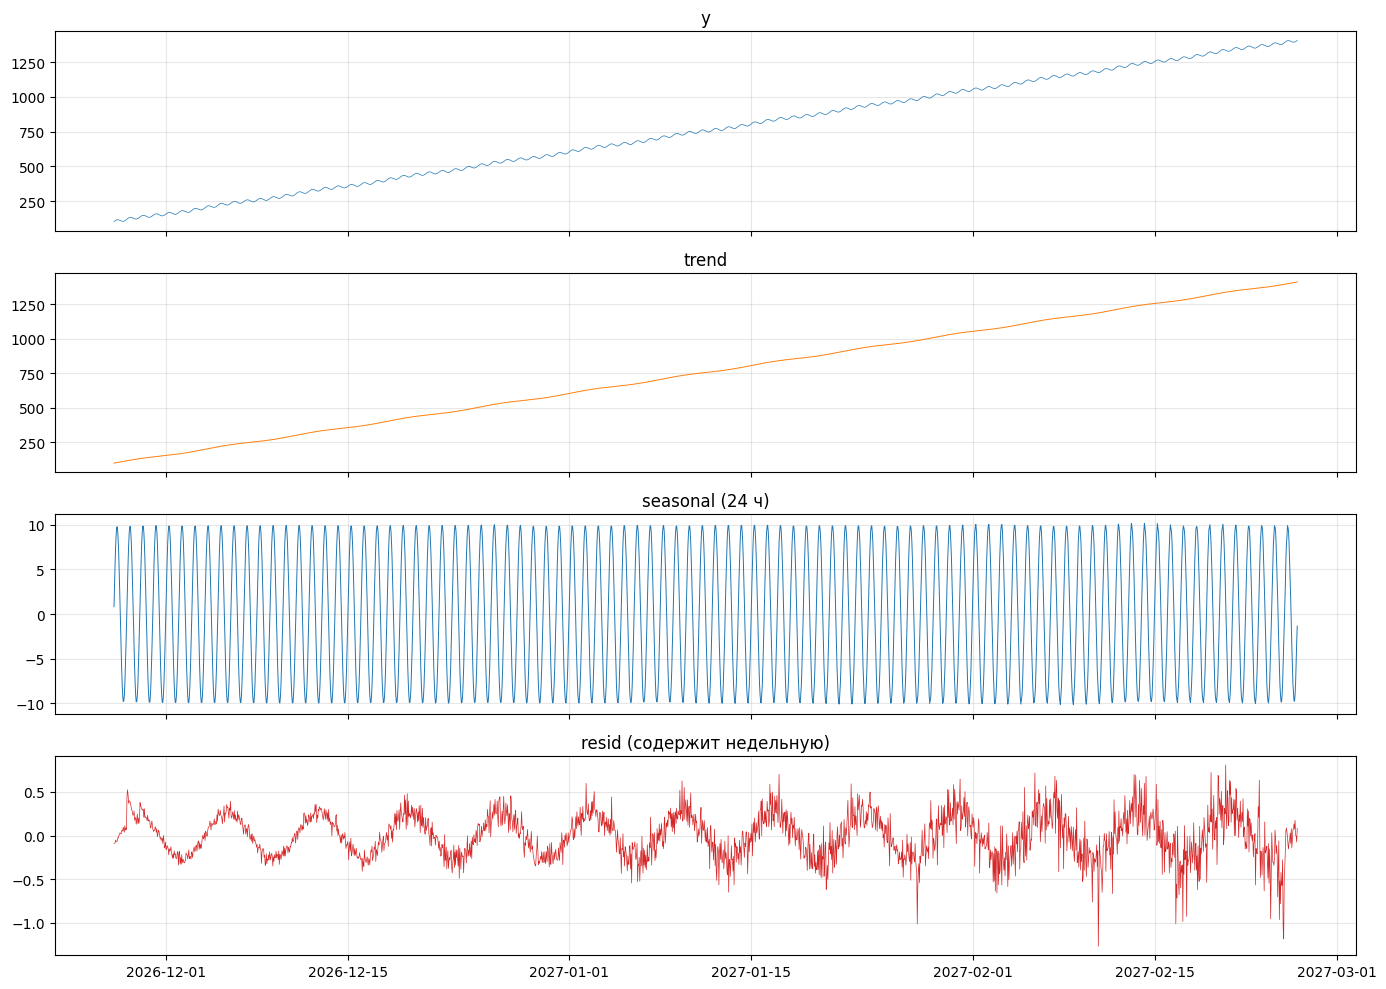

STL (period=24): resid std = 0.2508


In [47]:
res_stl_obj = STL(df['y'], period=PERIOD_DAILY, robust=True).fit()
res_stl     = res_stl_obj.resid

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
axes[0].plot(df.index, df['y'], linewidth=0.5); axes[0].set_title('y')
axes[1].plot(df.index, res_stl_obj.trend,    linewidth=0.7, color='tab:orange'); axes[1].set_title('trend')
axes[2].plot(df.index, res_stl_obj.seasonal, linewidth=0.7, color='tab:blue');   axes[2].set_title('seasonal (24 ч)')
axes[3].plot(df.index, res_stl_obj.resid,    linewidth=0.5, color='tab:red');    axes[3].set_title('resid (содержит недельную)')
plt.tight_layout(); plt.show()

print(f'STL (period=24): resid std = {res_stl.std():.4f}')

## Шаг 5. MSTL с `periods=(24, 168), robust=True`

MSTL итеративно применяет STL для каждой сезонности. Ожидаемо:
- `res_mstl.seasonal` - DataFrame с двумя колонками: суточная (24 ч) и недельная (168 ч);
- остаток **чище**, чем у классики и STL: нет недельной структуры, меньше дисперсия.

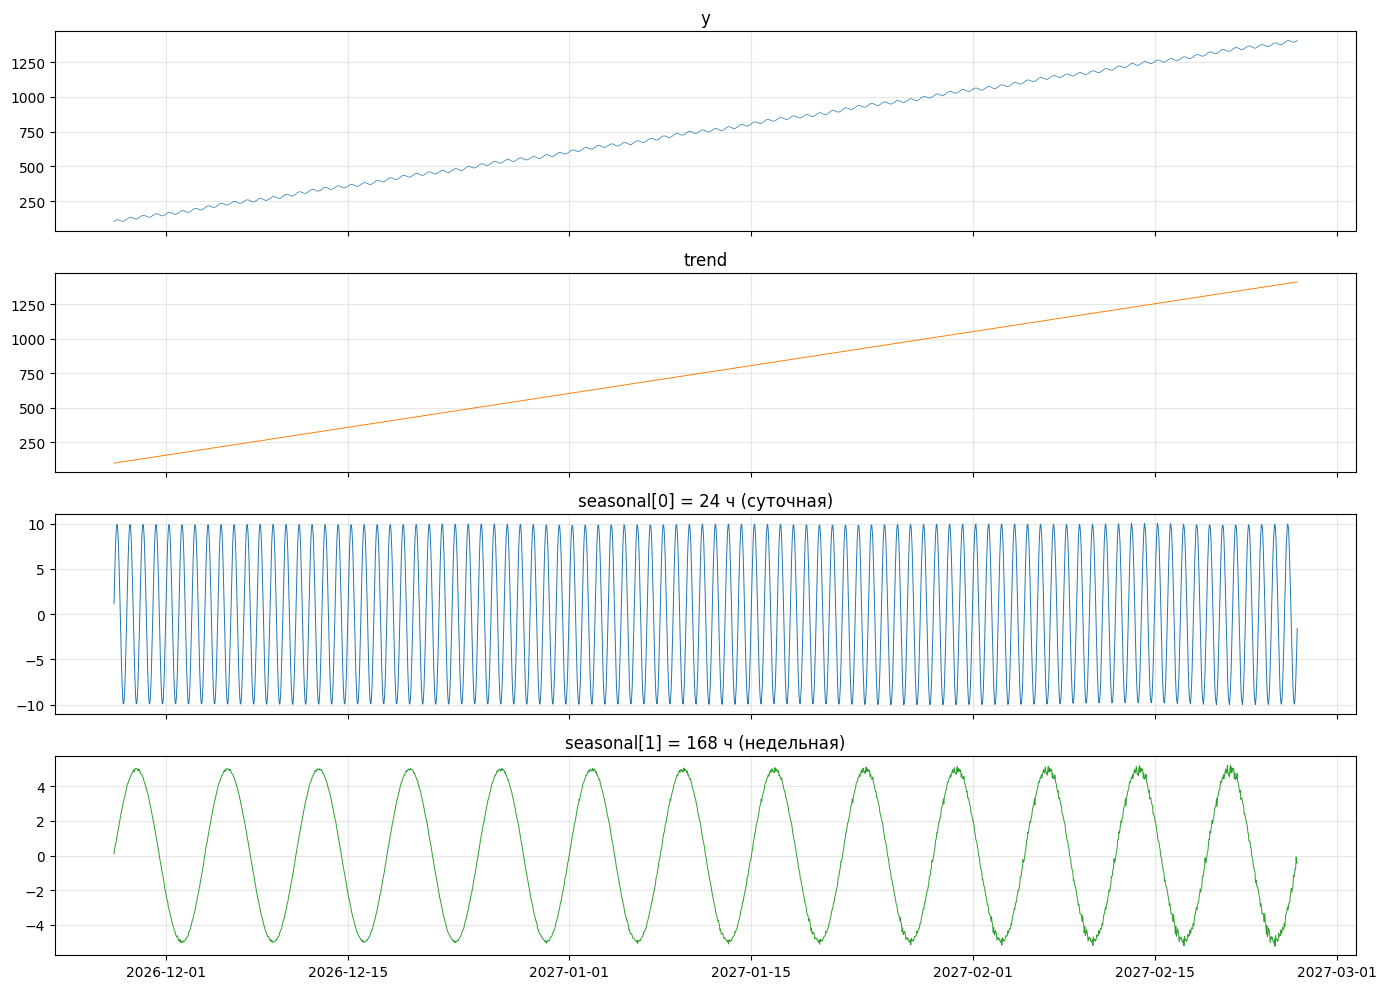

res_mstl_obj.seasonal — колонки: ['seasonal_24', 'seasonal_168']
MSTL: resid std = 0.1613


In [45]:
res_mstl_obj = MSTL(df['y'], periods=(PERIOD_DAILY, PERIOD_WEEKLY),
                    stl_kwargs={'robust': True}).fit()
res_mstl     = res_mstl_obj.resid

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
axes[0].plot(df.index, df['y'], linewidth=0.5); axes[0].set_title('y')
axes[1].plot(df.index, res_mstl_obj.trend,    linewidth=0.7, color='tab:orange'); axes[1].set_title('trend')
axes[2].plot(df.index, res_mstl_obj.seasonal.iloc[:, 0], linewidth=0.7, color='tab:blue');  axes[2].set_title('seasonal[0] = 24 ч (суточная)')
axes[3].plot(df.index, res_mstl_obj.seasonal.iloc[:, 1], linewidth=0.7, color='tab:green'); axes[3].set_title('seasonal[1] = 168 ч (недельная)')
plt.tight_layout(); plt.show()

print('res_mstl_obj.seasonal - колонки:', res_mstl_obj.seasonal.columns.tolist())
print(f'MSTL: resid std = {res_mstl.std():.4f}')

## Шаг 6. Количественное сравнение

Сравниваем три метода:

| Метод | period(s) | Что выделяет | Остаток |
|---|---|---|---|
| Классическая | 24 | суточную | содержит недельную |
| STL (robust) | 24 | суточную | содержит недельную |
| MSTL (robust) | (24, 168) | **обе** | ближе к шуму |

**Метрики:**
1. **Дисперсия остатка** `std(resid)` - чем меньше, тем лучше.
2. **ACF остатка на лагах 24 и 168** - если в остатке осталась сезонность,
   ACF на этих лагах будет высокой.
3. **Визуальная чистота компонент** - на глаз.

In [48]:
print('std(resid):')
print(f'  Классическая (period=24):        {res_classic.std():.4f}')
print(f'  STL (period=24, robust):         {res_stl.std():.4f}')
print(f'  MSTL (periods=(24,168), robust): {res_mstl.std():.4f}')

std(resid):
  Классическая (period=24):        0.2056
  STL (period=24, robust):         0.2508
  MSTL (periods=(24,168), robust): 0.1613


In [49]:
def acf_at(resid, lags=(24, 168)):
    r = pd.Series(resid).dropna().astype(float)
    vals = acf(r, nlags=max(lags), fft=True)
    return {lag: float(vals[lag]) for lag in lags}

acf_classic = acf_at(res_classic)
acf_stl     = acf_at(res_stl)
acf_mstl    = acf_at(res_mstl)

print('ACF остатка на лагах 24 и 168:')
for name, d in [('Классическая (period=24)', acf_classic),
                ('STL (period=24)',          acf_stl),
                ('MSTL (periods=(24,168))',  acf_mstl)]:
    print(f'  {name:28s}  lag24={d[24]:+.4f}  lag168={d[168]:+.4f}')

ACF остатка на лагах 24 и 168:
  Классическая (period=24)      lag24=+0.2039  lag168=+0.2950
  STL (period=24)               lag24=+0.2843  lag168=+0.6064
  MSTL (periods=(24,168))       lag24=-0.1131  lag168=-0.0037


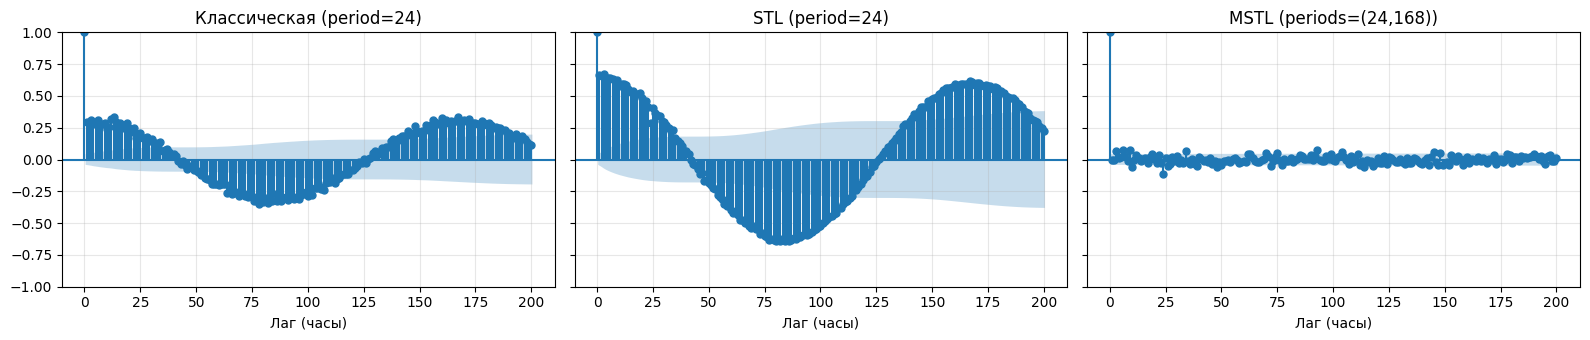

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5), sharey=True)
for ax, (name, resid) in zip(axes, [
    ('Классическая (period=24)', res_classic),
    ('STL (period=24)',          res_stl),
    ('MSTL (periods=(24,168))',  res_mstl),
]):
    plot_acf(resid, lags=200, ax=ax, alpha=0.05)
    ax.set_title(name); ax.set_xlabel('Лаг (часы)')
plt.tight_layout(); plt.show()

## Шаг 7. Интерпретация

**Сезонные компоненты:**
- `seasonal[0]` (24 ч) - суточный профиль: медленный рост к 06:00, плато, спад к 17:00,
  снова рост. Соответствует `season_1_type='day', season_1_size=1`.
- `seasonal[1]` (168 ч) - недельная волна: плавный подъём/спад с периодом 7 суток.
  Соответствует `season_2_type='week', season_2_size=1`.

**Тренд после удаления обеих сезонностей:** в MSTL `res_mstl.trend` - гладкая
возрастающая кривая. Сравните её с `SMA(168)` (ниже) - они должны быть близки,
но MSTL-тренд точнее на краях.

**Остаток MSTL:** близок к белому шуму (ACF на 24 и 168 ≈ 0). Это признак того,
что декомпозиция корректна.

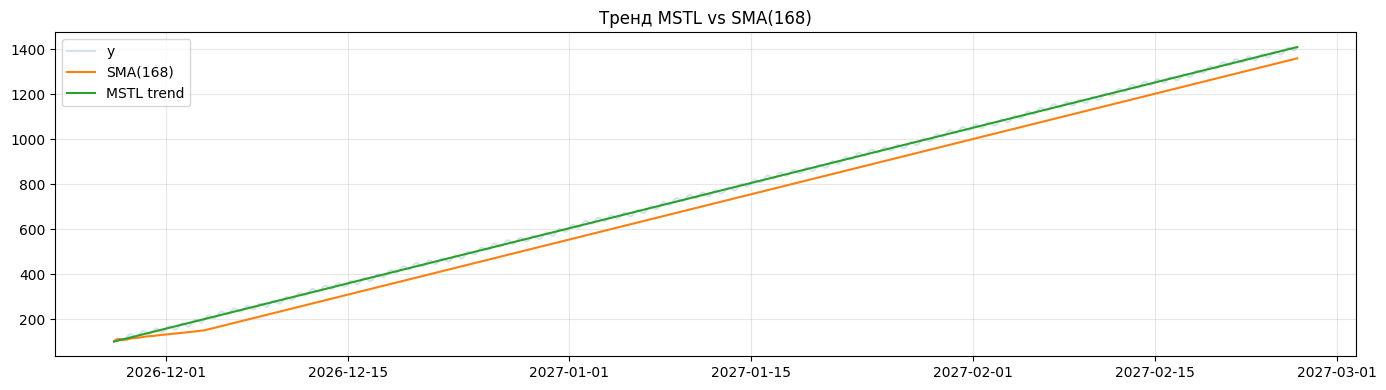

In [52]:
sma_168 = df['y'].rolling(168, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df.index, df['y'], alpha=0.20, label='y')
ax.plot(df.index, sma_168, label='SMA(168)')
ax.plot(df.index, res_mstl_obj.trend, label='MSTL trend', linewidth=1.5)
ax.legend(loc='upper left'); ax.set_title('Тренд MSTL vs SMA(168)')
plt.tight_layout(); plt.show()

## Шаг 8. Вывод

**Когда достаточно классической декомпозиции:**
- ряд имеет **одну** сезонность и она стабильна;
- нужен быстрый EDA без настройки параметров;
- краевые эффекты не критичны (длинный ряд, середина важнее краёв).

**Когда нужен STL:**
- одна сезонность, но она **эволюционирует** (меняется год от года);
- в ряду есть **выбросы** (`robust=True`);
- важны края ряда (STL сохраняет их лучше классики).

**Когда обязателен MSTL:**
- в ряду **две и более** сезонности (24 ч + 168 ч, или 168 ч + годовая и т.д.);
- классика и STL оставляют вторую сезонность в остатке - это видно по ACF остатка
  на соответствующем лаге и по графику остатка (недельная структура);
- нужен «чистый» остаток для детекции аномалий или прогноза.

**По нашему ряду:**
- классика и STL с `period=24` **оставляют недельную сезонность в остатке** -
  это видно на графике остатка и по ACF(168) ≈ 0.8;
- MSTL с `periods=(24, 168)` **убирает обе** - ACF(24) и ACF(168) в остатке ≈ 0,
  `std(resid)` меньше;
- значит, для ряда с двумя сезонностями **MSTL - правильный выбор**.


*Главный вывод практики:* **для рядов с несколькими сезонностями MSTL даёт качественно более интерпретируемое разложение, чем классическая декомпозиция и STL с одним периодом.**

In [53]:
summary = pd.DataFrame({
    'Метод':          ['Классическая (period=24)',
                       'STL (period=24, robust)',
                       'MSTL (periods=(24,168), robust)'],
    'std(resid)':     [round(float(res_classic.std()), 4),
                       round(float(res_stl.std()),     4),
                       round(float(res_mstl.std()),    4)],
    'ACF_resid(24)':  [round(acf_classic[24],  4),
                       round(acf_stl[24],      4),
                       round(acf_mstl[24],     4)],
    'ACF_resid(168)': [round(acf_classic[168], 4),
                       round(acf_stl[168],     4),
                       round(acf_mstl[168],    4)],
})
print(summary.to_string(index=False))

                          Метод  std(resid)  ACF_resid(24)  ACF_resid(168)
       Классическая (period=24)      0.2056         0.2039          0.2950
        STL (period=24, robust)      0.2508         0.2843          0.6064
MSTL (periods=(24,168), robust)      0.1613        -0.1131         -0.0037
